# 7) Barocaloric Screening

This notebook explores whether the isolated-molecule vibrational entropy and molecular-volume data in SCO ATLAS can help identify SCO complexes that may be interesting for barocaloric-effect (BCE) materials.

The frequency-resolved vibrational analysis has been moved to the end of notebook 4. Here, the gas-phase molecular volume is retained as an exploratory shape descriptor, not as a replacement for crystallographic volume changes. The goal is to identify candidates worth deeper solid-state analysis.

In [1]:
from pathlib import Path
import csv

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scope
from scipy.spatial import ConvexHull, QhullError

from scope.thermodynamics import get_Svib
from scope.elementdata import ElementData


In [2]:
project_path = Path('/Users/sergivela/Documents/SCOPE/Database_SCO')
root_path = project_path / 'Analysis/1-Analyse_Database'
outputs_path = root_path / 'Outputs'
figures_path = project_path / 'Figures'
env_path = project_path / 'Data/scope_env_atlas.npy'
thermo_csv_path = outputs_path / 'unique_thermodynamic_data.csv'

env = scope.read_write.load_binary(str(env_path))

## 1. Working Definitions

For each system we use the optimized HS and LS isolated-molecule states named `b3lyp_opt`. Vibrational entropy is evaluated at 298.15 K with SCOPE's `scope.thermodynamics.get_Svib` harmonic-oscillator expression. Imaginary frequencies are folded through their absolute values and frequencies below 1 cm$^{-1}$ are ignored, matching the SCOPE thermal-data workflow.

The molecular volume descriptor is the convex-hull volume of the optimized nuclear coordinates, converted to cm$^3$ mol$^{-1}$. For BCE-oriented ranking, the entropy term is taken as an approximate total molecular entropy change, $\Delta S_{\mathrm{total}} \approx \Delta S_{\mathrm{vib}} + R\ln(5)$, corresponding to the electronic spin degeneracy change for an Fe(II) LS singlet to HS quintet transition.

In [3]:
TEMPERATURE = 298.15
MIN_FREQ_CM = 1.0
DENTICITIES_TO_COMPARE = ['1', '2', '3', '6']
ENTROPY_METHOD = 'scope.thermodynamics.get_Svib(default harmonic oscillator, abs freqs, >=1 cm-1)'
GAS_CONSTANT_JMOLK = 8.31446261815324
DSELEC_FEII_JMOLK = GAS_CONSTANT_JMOLK * np.log(5.0)

# 1 A^3 per molecule = 0.602214 cm^3 mol^-1
ANG3_TO_CM3_MOL = 0.602214076
REQUIRED_SYSTEM_COLUMNS = {
    'homoleptic',
    'total_charge',
    'charged',
    'molecular_weight_gmol',
    'dStotal_298_JmolK',
    'dStotal_mass_JkgK',
    'dV_hull_cm3g',
    'BCE_metric_mass',
}
SCREENING_EXPORT_COLUMNS = {
    'refcode': 'refcode',
    'path': 'path',
    'denticity': 'denticity',
    'homoleptic': 'homoleptic',
    'total_charge': 'total_charge',
    'charged': 'charged',
    'entropy_method': 'entropy_method',
    'dHelec_kJmol': 'dHelec[kJ·mol-1]',
    'dHvib_298_kJmol': 'dHvib_298K[kJ·mol-1]',
    'dSvibT_298_kJmol': 'dSvibT_298K[kJ·mol-1]',
    'dSvib_from_thermo_298_JmolK': 'dSvib_from_thermo_298K[J·mol-1·K-1]',
    'dSelec_FeII_JmolK': 'dSelec_FeII[J·mol-1·K-1]',
    'HS_Svib_298_JmolK': 'HS_Svib_298K[J·mol-1·K-1]',
    'LS_Svib_298_JmolK': 'LS_Svib_298K[J·mol-1·K-1]',
    'dSvib_298_JmolK': 'dSvib_298K[J·mol-1·K-1]',
    'dStotal_298_JmolK': 'dStotal_298K[J·mol-1·K-1]',
    'molecular_weight_gmol': 'molecular_weight[g·mol-1]',
    'dSvib_mass_JkgK': 'dSvib_mass_298K[J·kg-1·K-1]',
    'dStotal_mass_JkgK': 'dStotal_mass_298K[J·kg-1·K-1]',
    'T12_K': 'T12[K]',
    'HS_hull_volume_A3': 'HS_hull_volume[A3]',
    'LS_hull_volume_A3': 'LS_hull_volume[A3]',
    'dV_hull_A3': 'dV_hull[A3]',
    'dV_hull_cm3mol': 'dV_hull[cm3·mol-1]',
    'dV_hull_cm3g': 'dV_hull[cm3·g-1]',
    'BCE_metric_molar': 'BCE_metric[J·cm3·mol-2·K-1]',
    'BCE_metric_mass': 'BCE_metric[J·cm3·kg-1·g-1·K-1]',
}
SCREENING_IMPORT_COLUMNS = {value: key for key, value in SCREENING_EXPORT_COLUMNS.items()}


elemdatabase = ElementData()


## 2. Helper Functions


In [4]:
def read_csv(path):
    with open(path, newline='') as f:
        return list(csv.DictReader(f))

def load_screening_csv(path):
    return pd.read_csv(path).rename(columns=SCREENING_IMPORT_COLUMNS)

def write_screening_csv(dataframe, path):
    columns = [col for col in SCREENING_EXPORT_COLUMNS if col in dataframe.columns]
    (
        dataframe[columns]
        .rename(columns=SCREENING_EXPORT_COLUMNS)
        .to_csv(path, index=False)
    )

def resolve_system_path(path_from_csv):
    path = Path(path_from_csv)
    if path.is_absolute() and path.exists():
        return path
    return project_path / str(path_from_csv).lstrip('/')

def as_float(value):
    if value in (None, '', 'None'):
        return np.nan
    return float(value)

def get_hs_ls_b3lyp_states(system):
    found_hs, hs_mol = system.find_source('ref_hs_mol')
    found_ls, ls_mol = system.find_source('ref_ls_mol')
    if not (found_hs and found_ls):
        raise ValueError('Missing HS or LS reference molecule')

    found_hs_state, hs_state = hs_mol.find_state('b3lyp_opt')
    found_ls_state, ls_state = ls_mol.find_state('b3lyp_opt')
    if not (found_hs_state and found_ls_state):
        raise ValueError('Missing HS or LS b3lyp_opt state')

    return hs_state, ls_state

def thermal_frequencies_cm(state, min_freq_cm=MIN_FREQ_CM):
    # Match SCOPE thermal-data convention: imaginary modes are folded through abs(),
    # and get_Svib itself ignores frequencies below 1 cm^-1.
    freqs = np.abs(np.asarray(state.freqs_cm, dtype=float))
    return freqs[freqs >= min_freq_cm]

def scope_svib_jmolK(freqs_cm, temperature=TEMPERATURE):
    freqs_cm = np.asarray(freqs_cm, dtype=float)
    if len(freqs_cm) == 0:
        return 0.0
    return 1000.0 * get_Svib(freqs_cm, temperature, freq_units='cm', outunits='kj').value

def convex_hull_volume_ang3(state):
    coords = np.asarray(state.coord, dtype=float)
    if coords.shape[0] < 4:
        return np.nan
    try:
        return float(ConvexHull(coords).volume)
    except QhullError:
        return np.nan

def molecular_weight_gmol(state):
    return float(sum(elemdatabase.elementweight[label] for label in state.labels))

def molecule_total_charge(molecule):
    for attr in ('total_charge', 'charge'):
        if hasattr(molecule, attr):
            charge = getattr(molecule, attr)
            if charge is not None:
                return int(round(float(charge)))
    return np.nan

def thermo_column(row, startswith):
    matches = [key for key in row.keys() if key.startswith(startswith)]
    if not matches:
        raise KeyError(f'Could not find thermodynamic column starting with {startswith!r}. Available: {list(row.keys())}')
    return matches[0]

def dsvib_t_from_thermo_row(row):
    return as_float(row[thermo_column(row, 'dSvib')])

def svib_from_thermo_row(row):
    # The source notebook stores T*dSvib at 298 K in kJ/mol.
    # Convert to J mol^-1 K^-1 for BCE-style comparisons.
    return 1000.0 * dsvib_t_from_thermo_row(row) / TEMPERATURE


## 3. Load Thermodynamic Entries

The extraction step keeps all finished systems so that the candidate screening can optionally include or exclude heteroleptic complexes.

In [5]:
thermo_rows = read_csv(thermo_csv_path)
analysis_rows = [row for row in thermo_rows if row['status'] == 'finished']

print(f'Total thermodynamic rows: {len(thermo_rows)}')
print(f'Finished systems for BCE screening: {len(analysis_rows)}')
pd.DataFrame(analysis_rows)[['homoleptic', 'denticity']].value_counts().sort_index()


Total thermodynamic rows: 604
Finished systems for BCE screening: 604


homoleptic  denticity
False       unknown      303
True        1             12
            2             50
            3            208
            6             31
Name: count, dtype: int64

## 4. Extract Entropy And Molecular-Volume Descriptors

The system-level extraction is cached to CSV. Set `overwrite = True` to rebuild it from the SCOPE objects. Frequency-bin data are generated separately at the end of notebook 4.

In [ ]:
overwrite = False
system_csv = outputs_path / 'bce_vibrational_screening_data.csv'

if system_csv.exists() and not overwrite:
    try:
        system_df = load_screening_csv(system_csv)
    except pd.errors.EmptyDataError:
        print('Cached entropy data are empty; rebuilding with SCOPE get_Svib.')
        overwrite = True
    else:
        missing_columns = REQUIRED_SYSTEM_COLUMNS - set(system_df.columns)
        if 'entropy_method' not in system_df.columns or set(system_df['entropy_method'].dropna()) != {ENTROPY_METHOD}:
            print('Cached entropy data were generated with an older method; rebuilding with SCOPE get_Svib.')
            overwrite = True
        elif missing_columns:
            print(f'Cached entropy data are missing new columns {sorted(missing_columns)}; rebuilding.')
            overwrite = True
        else:
            system_df['denticity'] = system_df['denticity'].astype(str)
            system_df['homoleptic'] = system_df['homoleptic'].astype(bool)
            print(f'Loaded {len(system_df)} systems from {system_csv}')

if overwrite or not system_csv.exists():
    system_records = []
    failures = []

    for row in analysis_rows:
        refcode = row.get('refcode', row.get('id'))
        try:
            system = scope.read_write.load_binary(str(resolve_system_path(row['path'])))
            system.set_paths_from_environment(env)
            hs_state, ls_state = get_hs_ls_b3lyp_states(system)
            found_hs_mol, hs_mol = system.find_source('ref_hs_mol')
            if not found_hs_mol:
                raise ValueError('Missing HS reference molecule')
            total_charge = molecule_total_charge(hs_mol)
            charged = bool(np.isfinite(total_charge) and total_charge != 0)

            hs_freqs = thermal_frequencies_cm(hs_state)
            ls_freqs = thermal_frequencies_cm(ls_state)
            hs_svib_jmolk = scope_svib_jmolK(hs_freqs)
            ls_svib_jmolk = scope_svib_jmolK(ls_freqs)
            dsvib_jmolk = hs_svib_jmolk - ls_svib_jmolk

            hs_volume_ang3 = convex_hull_volume_ang3(hs_state)
            ls_volume_ang3 = convex_hull_volume_ang3(ls_state)
            d_volume_ang3 = hs_volume_ang3 - ls_volume_ang3
            d_volume_cm3mol = d_volume_ang3 * ANG3_TO_CM3_MOL

            mw_gmol = molecular_weight_gmol(hs_state)
            dsvib_mass_jkgk = 1000.0 * dsvib_jmolk / mw_gmol
            d_volume_cm3g = d_volume_cm3mol / mw_gmol

            dsvib_from_thermo_jmolk = svib_from_thermo_row(row)
            dselec_jmolk = DSELEC_FEII_JMOLK
            dstotal_jmolk = dsvib_jmolk + dselec_jmolk
            dstotal_mass_jkgk = 1000.0 * dstotal_jmolk / mw_gmol

            system_records.append({
                'refcode': refcode,
                'path': row['path'],
                'denticity': str(row['denticity']),
                'homoleptic': row['homoleptic'] == 'True',
                'total_charge': total_charge,
                'charged': charged,
                'entropy_method': ENTROPY_METHOD,
                'dHelec_kJmol': as_float(row['dHelec[kJ/mol]']),
                'dHvib_298_kJmol': as_float(row['dHvib[kJ/mol](T=298K)']),
                'dSvibT_298_kJmol': dsvib_t_from_thermo_row(row),
                'dSvib_from_thermo_298_JmolK': dsvib_from_thermo_jmolk,
                'HS_Svib_298_JmolK': hs_svib_jmolk,
                'LS_Svib_298_JmolK': ls_svib_jmolk,
                'dSvib_298_JmolK': dsvib_jmolk,
                'dSelec_FeII_JmolK': dselec_jmolk,
                'dStotal_298_JmolK': dstotal_jmolk,
                'molecular_weight_gmol': mw_gmol,
                'dSvib_mass_JkgK': dsvib_mass_jkgk,
                'dStotal_mass_JkgK': dstotal_mass_jkgk,
                'T12_K': as_float(row['T12[K]']),
                'HS_hull_volume_A3': hs_volume_ang3,
                'LS_hull_volume_A3': ls_volume_ang3,
                'dV_hull_A3': d_volume_ang3,
                'dV_hull_cm3mol': d_volume_cm3mol,
                'dV_hull_cm3g': d_volume_cm3g,
                'BCE_metric_molar': dstotal_jmolk * max(d_volume_cm3mol, 0),
                'BCE_metric_mass': dstotal_mass_jkgk * max(d_volume_cm3g, 0),
            })
        except Exception as exc:
            failures.append((refcode, repr(exc)))

    if not system_records:
        raise RuntimeError(f'No systems were extracted. First failures: {failures[:10]}')

    system_df = pd.DataFrame(system_records)
    write_screening_csv(system_df, system_csv)

    print(f'Extracted {len(system_df)} systems')
    print(f'Failures: {len(failures)}')
    print(f'Wrote {system_csv}')
    failures[:10]

## 5. Candidate Screening For BCE

For a real BCE material, the key solid-state quantities are transition entropy, crystal-volume change, hysteresis, and reversibility. Here we only have gas-phase vibrational entropy and an approximate molecular volume proxy. Therefore, the following ranking should be interpreted as a **triage list**, not as a BCE prediction.

In [12]:
screening_columns = [
    'refcode', 'denticity', 'homoleptic', 'charged', 'molecular_weight_gmol',
    'dStotal_mass_JkgK', 'dV_hull_cm3g', 'BCE_metric_mass',
    'T12_K', 'dSvib_mass_JkgK', 'dHelec_kJmol', 'dHvib_298_kJmol'
]

# Optional filters for the screening table.
only_homoleptic = False
only_heteroleptic = False
only_neutral = False
only_charged = False
only_good_t12 = False
T12_WINDOW = (150, 350)

candidate_df = system_df.replace([np.inf, -np.inf], np.nan).copy()
if only_homoleptic:
    candidate_df = candidate_df[candidate_df['homoleptic'] == True]
if only_heteroleptic:
    candidate_df = candidate_df[candidate_df['homoleptic'] == False]
if only_neutral:
    candidate_df = candidate_df[candidate_df['charged'] == False]
if only_charged:
    candidate_df = candidate_df[candidate_df['charged'] == True]
if only_good_t12:
    candidate_df = candidate_df[candidate_df['T12_K'].between(*T12_WINDOW)]

candidate_df = (
    candidate_df
    .dropna(subset=['dStotal_mass_JkgK', 'dV_hull_cm3g', 'molecular_weight_gmol'])
    .sort_values(['BCE_metric_mass', 'dStotal_mass_JkgK', 'dV_hull_cm3g'], ascending=[False, False, False])
)

candidate_df[screening_columns].head(40)


,refcode,denticity,homoleptic,charged,molecular_weight_gmol,dStotal_mass_JkgK,dV_hull_cm3g,BCE_metric_mass,T12_K,dSvib_mass_JkgK,dHelec_kJmol,dHvib_298_kJmol
444,RAPXOY,1,True,True,302.1462,317.351480,0.066759,21.185931,NaN,273.062949,22.562997,-6.385336
270,JOWGEH,2,True,True,308.1912,320.304192,0.035332,11.316922,NaN,276.884356,67.576673,-8.327020
442,RANCUG,2,True,True,425.2968,254.471233,0.044139,11.232222,133.0,223.007062,21.898798,-6.440087
110,DOQRAC,unknown,False,True,350.2680,251.313064,0.044349,11.145589,202.0,213.109142,25.730138,-7.674739
2,ADAQUU,unknown,False,False,584.4900,125.031778,0.082880,10.362690,166.0,102.137270,17.238562,-4.626926
34,BAKGUR,2,True,True,509.4504,203.855947,0.045480,9.271279,NaN,177.589187,10.621330,-6.583004
91,DEDMAC,unknown,False,False,556.5182,178.897809,0.049663,8.884575,63.0,154.852574,12.511296,-3.825807
211,HIPXOW,1,True,True,560.3082,202.702347,0.042701,8.655543,104.0,178.819757,18.782120,-5.455274
609,YOYVEQ,unknown,False,True,396.2500,194.233715,0.043684,8.484933,451.0,160.463087,40.322038,-5.343933
453,RIYTIC,unknown,False,True,418.3016,226.038467,0.037045,8.373675,379.0,194.048125,42.350447,-6.412754


### 5.1 Original Screening Map

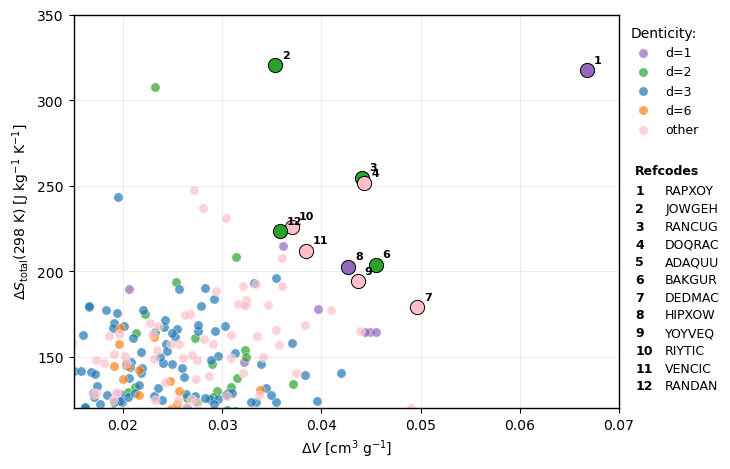

In [13]:
fig, ax = plt.subplots(figsize=(7.4, 4.8), tight_layout=True)
colors = {'1': 'tab:purple', '2': 'tab:green', '3': 'tab:blue', '6': 'tab:orange', 'other': 'pink'}

# Optional filters for the screening map.
only_homoleptic = False
only_heteroleptic = False
only_neutral = False
only_charged = False
only_good_t12 = False
T12_WINDOW = (150, 350)

plot_df = system_df.dropna(subset=['dV_hull_cm3g', 'dStotal_mass_JkgK']).copy()
if only_homoleptic:
    plot_df = plot_df[plot_df['homoleptic'] == True]
if only_heteroleptic:
    plot_df = plot_df[plot_df['homoleptic'] == False]
if only_neutral:
    plot_df = plot_df[plot_df['charged'] == False]
if only_charged:
    plot_df = plot_df[plot_df['charged'] == True]
if only_good_t12:
    plot_df = plot_df[plot_df['T12_K'].between(*T12_WINDOW)]
#plot_df = plot_df[(plot_df['dV_hull_cm3g'] > 0.015) & (plot_df['dStotal_mass_JkgK'] > 95)]
plot_df['plot_denticity'] = np.where(plot_df['homoleptic'], plot_df['denticity'].astype(str), 'other')
plot_order = [d for d in DENTICITIES_TO_COMPARE + ['other'] if d in set(plot_df['plot_denticity'])]

for denticity in plot_order:
    sub = plot_df[plot_df['plot_denticity'] == denticity]
    ax.scatter(
        sub['dV_hull_cm3g'],
        sub['dStotal_mass_JkgK'],
        label=('other' if denticity == 'other' else f'd={denticity}'),
        color=colors.get(denticity, '0.5'),
        edgecolor='white',
        linewidth=0.4,
        alpha=0.70,
        s=45,
    )

use_number_labels = True
n_labels = 12
label_df = plot_df.sort_values('BCE_metric_mass', ascending=False).head(n_labels).reset_index(drop=True)
label_df['plot_label'] = np.arange(1, len(label_df) + 1)

for _, row in label_df.iterrows():
    point_color = colors.get('other' if not row['homoleptic'] else str(row['denticity']), '0.5')
    ax.scatter(
        row['dV_hull_cm3g'],
        row['dStotal_mass_JkgK'],
        color=point_color,
        edgecolor='black',
        linewidth=0.7,
        s=105,
        zorder=4,
    )
    if use_number_labels:
        ax.annotate(
            str(int(row['plot_label'])),
            (row['dV_hull_cm3g'], row['dStotal_mass_JkgK']),
            xytext=(5, 4),
            textcoords='offset points',
            ha='left',
            va='bottom',
            fontsize=8,
            fontweight='bold',
            color='black',
            zorder=5,
        )
    else:
        ax.annotate(
            row['refcode'],
            (row['dV_hull_cm3g'], row['dStotal_mass_JkgK']),
            xytext=(5, 4),
            textcoords='offset points',
            fontsize=9,
            arrowprops=dict(arrowstyle='-', linewidth=0.7, color='0.35'),
        )

if use_number_labels and not label_df.empty:
    key_x = 1.03
    key_y = 0.62
    line_height = 0.045
    ax.text(
        key_x,
        key_y,
        'Refcodes',
        transform=ax.transAxes,
        ha='left',
        va='top',
        fontsize=9,
        fontweight='bold',
    )
    for idx, row in label_df.iterrows():
        y = key_y - (idx + 1.15) * line_height
        ax.text(
            key_x,
            y,
            f"{int(row['plot_label'])}",
            transform=ax.transAxes,
            ha='left',
            va='top',
            fontsize=9,
            fontweight='bold',
        )
        ax.text(
            key_x + 0.055,
            y,
            row['refcode'],
            transform=ax.transAxes,
            ha='left',
            va='top',
            fontsize=9,
        )

ax.set_xlim(0.015, 0.07)
ax.set_ylim(120, 350)
ax.set_xlabel(r'$\Delta V$ [cm$^3$ g$^{-1}$]')
ax.set_ylabel(r'$\Delta S_{\mathrm{total}}$(298 K) [J kg$^{-1}$ K$^{-1}$]')
ax.legend(title='Denticity:', loc='upper left', bbox_to_anchor=(1.0, 1.0), frameon=False, fontsize=9, title_fontsize=10)
ax.grid(alpha=0.22)
for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color('black')
    spine.set_linewidth(1.0)
figures_path.mkdir(exist_ok=True)
plt.savefig(figures_path / 'BCE_screening_mass_specific.png', dpi=400, bbox_inches='tight')
plt.show()


**Caption.** Exploratory barocaloric-effect screening map using mass-specific quantities, focused on the upper-right candidate region. The y-axis is the estimated total entropy change, $\Delta S_{\mathrm{total}} \approx \Delta S_{\mathrm{vib}} + R\ln(5)$, in J kg$^{-1}$ K$^{-1}$, and the x-axis is the convex-hull molecular-volume change in cm$^3$ g$^{-1}$. Labels mark the highest-ranked systems according to the mass-specific entropy-volume BCE metric.


**Manuscript note.** The BCE ranking uses the total molecular entropy estimate, $\Delta S_{\mathrm{total}} \approx \Delta S_{\mathrm{vib}} + R\ln(5)$, rather than the vibrational contribution alone. The electronic spin term is constant for the Fe(II) LS singlet to HS quintet transition, so it has little effect on trends driven by ligand-dependent vibrations, but it changes absolute mass-specific entropy values and therefore the derived BCE metric. The transition temperature remains a separate practical filter: RAPXOY is the strongest molecular metric candidate but lacks a useful $T_{1/2}$ entry, whereas YEQKIR and IVIBAT01 combine high scores with experimentally relevant $T_{1/2}$ values.


### 5.2 Neutral-Complex Screening Map

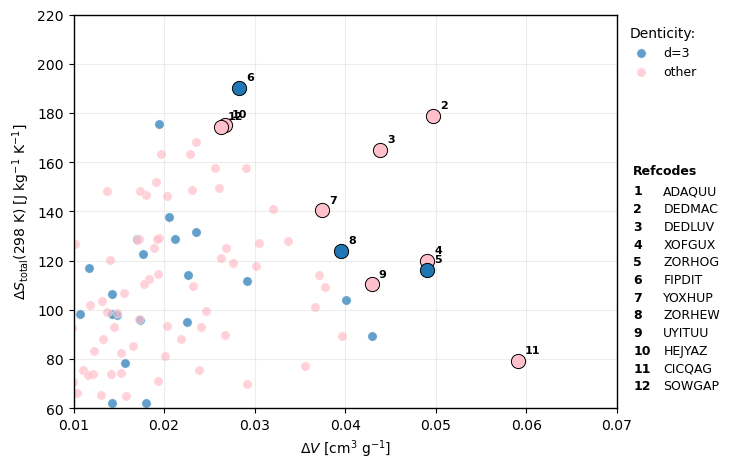

In [14]:
fig, ax = plt.subplots(figsize=(7.4, 4.8), tight_layout=True)
colors = {'1': 'tab:purple', '2': 'tab:green', '3': 'tab:blue', '6': 'tab:orange', 'other': 'pink'}

# Optional filters for the screening map.
only_homoleptic = False
only_heteroleptic = False
only_neutral = True
only_charged = False
only_good_t12 = False
T12_WINDOW = (150, 350)

plot_df = system_df.dropna(subset=['dV_hull_cm3g', 'dStotal_mass_JkgK']).copy()
if only_homoleptic:     plot_df = plot_df[plot_df['homoleptic'] == True]
if only_heteroleptic:   plot_df = plot_df[plot_df['homoleptic'] == False]
if only_neutral:        plot_df = plot_df[plot_df['charged'] == False]
if only_charged:        plot_df = plot_df[plot_df['charged'] == True]
if only_good_t12:       plot_df = plot_df[plot_df['T12_K'].between(*T12_WINDOW)]

plot_df['plot_denticity'] = np.where(plot_df['homoleptic'], plot_df['denticity'].astype(str), 'other')
plot_order = [d for d in DENTICITIES_TO_COMPARE + ['other'] if d in set(plot_df['plot_denticity'])]

for denticity in plot_order:
    sub = plot_df[plot_df['plot_denticity'] == denticity]
    ax.scatter(
        sub['dV_hull_cm3g'],
        sub['dStotal_mass_JkgK'],
        label=('other' if denticity == 'other' else f'd={denticity}'),
        color=colors.get(denticity, '0.5'),
        edgecolor='white',
        linewidth=0.4,
        alpha=0.70,
        s=45,
    )

use_number_labels = True
n_labels = 12
label_df = plot_df.sort_values('BCE_metric_mass', ascending=False).head(n_labels).reset_index(drop=True)
label_df['plot_label'] = np.arange(1, len(label_df) + 1)

for _, row in label_df.iterrows():
    point_color = colors.get('other' if not row['homoleptic'] else str(row['denticity']), '0.5')
    ax.scatter(
        row['dV_hull_cm3g'],
        row['dStotal_mass_JkgK'],
        color=point_color,
        edgecolor='black',
        linewidth=0.7,
        s=105,
        zorder=4,
    )
    if use_number_labels:
        ax.annotate(
            str(int(row['plot_label'])),
            (row['dV_hull_cm3g'], row['dStotal_mass_JkgK']),
            xytext=(5, 4),
            textcoords='offset points',
            ha='left',
            va='bottom',
            fontsize=8,
            fontweight='bold',
            color='black',
            zorder=5,
        )
    else:
        ax.annotate(
            row['refcode'],
            (row['dV_hull_cm3g'], row['dStotal_mass_JkgK']),
            xytext=(5, 4),
            textcoords='offset points',
            fontsize=9,
            arrowprops=dict(arrowstyle='-', linewidth=0.7, color='0.35'),
        )

if use_number_labels and not label_df.empty:
    key_x = 1.03
    key_y = 0.62
    line_height = 0.045
    ax.text(
        key_x,
        key_y,
        'Refcodes',
        transform=ax.transAxes,
        ha='left',
        va='top',
        fontsize=9,
        fontweight='bold',
    )
    for idx, row in label_df.iterrows():
        y = key_y - (idx + 1.15) * line_height
        ax.text(
            key_x,
            y,
            f"{int(row['plot_label'])}",
            transform=ax.transAxes,
            ha='left',
            va='top',
            fontsize=9,
            fontweight='bold',
        )
        ax.text(
            key_x + 0.055,
            y,
            row['refcode'],
            transform=ax.transAxes,
            ha='left',
            va='top',
            fontsize=9,
        )

ax.set_xlim(0.01, 0.07)
ax.set_ylim(60, 220)
ax.set_xlabel(r'$\Delta V$ [cm$^3$ g$^{-1}$]')
ax.set_ylabel(r'$\Delta S_{\mathrm{total}}$(298 K) [J kg$^{-1}$ K$^{-1}$]')
ax.legend(title='Denticity:', loc='upper left', bbox_to_anchor=(1.0, 1.0), frameon=False, fontsize=9, title_fontsize=10)
ax.grid(alpha=0.22)
for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color('black')
    spine.set_linewidth(1.0)
figures_path.mkdir(exist_ok=True)
plt.savefig(figures_path / 'BCE_screening_mass_specific_neutral.png', dpi=400, bbox_inches='tight')
plt.show()

## 6. Working Interpretation

If monodentate complexes remain enriched at high \(\Delta S_{\mathrm{vib}}\), the likely microscopic origin is an increased number and/or softening of low-frequency modes in the HS state relative to LS. These modes may include ligand reorientation, Fe-ligand breathing, and other soft intramolecular distortions that are easier to activate when each ligand is less constrained by multidentate chelation.

For BCE screening, large \(\Delta S_{\mathrm{vib}}\) is encouraging because it increases the possible entropy change across the SCO transition. However, BCE also requires pressure sensitivity, which depends on \(\Delta V/\Delta S\). The gas-phase convex-hull volume difference used here can only flag systems whose molecular shape expands substantially from LS to HS; it cannot capture packing, solvent, counterions, lattice phonons, hysteresis, or reversibility. Therefore, systems that combine large \(\Delta S_{\mathrm{vib}}\), positive gas-phase \(\Delta V\), and suitable experimental \(T_{1/2}\) should be treated as candidates for deeper solid-state analysis rather than as confirmed BCE materials.

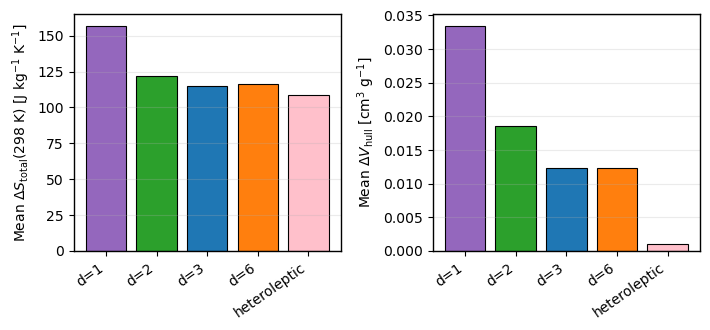

,mean_dStotal_mass_JkgK,mean_dV_hull_cm3g,n
plot_denticity,,,
1,156.983343,0.033495,13
2,121.549318,0.018529,53
3,114.816773,0.012365,217
6,116.168085,0.012334,35
other,108.513969,0.001080,315


In [15]:
# Denticity-resolved BCE descriptor averages

summary_df = system_df.replace([np.inf, -np.inf], np.nan).copy()
summary_df = summary_df.dropna(subset=['dStotal_mass_JkgK', 'dV_hull_cm3g'])
summary_df['plot_denticity'] = np.where(summary_df['homoleptic'], summary_df['denticity'].astype(str), 'other')

plot_order = [d for d in DENTICITIES_TO_COMPARE + ['other'] if d in set(summary_df['plot_denticity'])]
plot_labels = [('heteroleptic' if d == 'other' else f'd={d}') for d in plot_order]
plot_colors = {'1': 'tab:purple', '2': 'tab:green', '3': 'tab:blue', '6': 'tab:orange', 'other': 'pink'}

average_df = (
    summary_df
    .groupby('plot_denticity', sort=False)
    .agg(
        mean_dStotal_mass_JkgK=('dStotal_mass_JkgK', 'mean'),
        mean_dV_hull_cm3g=('dV_hull_cm3g', 'mean'),
        n=('refcode', 'count'),
    )
    .reindex(plot_order)
)

fig, axs = plt.subplots(1, 2, figsize=(7.2, 3.4), tight_layout=True)
x_pos = np.arange(len(plot_order))
bar_colors = [plot_colors.get(d, '0.6') for d in plot_order]

axs[0].bar(x_pos, average_df['mean_dStotal_mass_JkgK'], color=bar_colors, edgecolor='black', linewidth=0.8)
axs[0].set_ylabel(r'Mean $\Delta S_{\mathrm{total}}$(298 K) [J kg$^{-1}$ K$^{-1}$]')
axs[0].set_xticks(x_pos, plot_labels, rotation=35, ha='right')
axs[0].grid(axis='y', alpha=0.25)

axs[1].bar(x_pos, average_df['mean_dV_hull_cm3g'], color=bar_colors, edgecolor='black', linewidth=0.8)
axs[1].set_ylabel(r'Mean $\Delta V_{\mathrm{hull}}$ [cm$^3$ g$^{-1}$]')
axs[1].set_xticks(x_pos, plot_labels, rotation=35, ha='right')
axs[1].grid(axis='y', alpha=0.25)

for ax in axs:
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_color('black')
        spine.set_linewidth(1.0)

figures_path.mkdir(exist_ok=True)
plt.savefig(figures_path / 'BCE_denticity_average_descriptors.png', dpi=400)
plt.show()

average_df



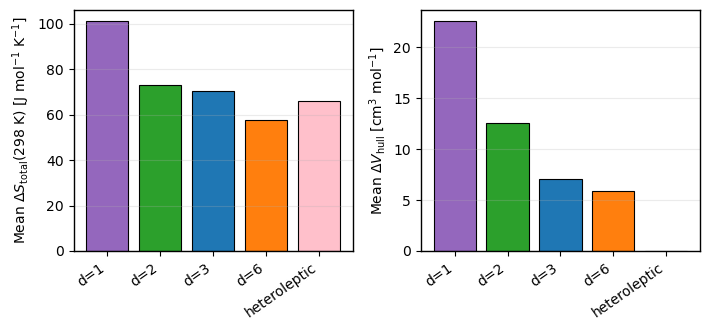

,mean_dStotal_JmolK,mean_dV_hull_cm3mol,n
plot_denticity,,,
1,101.062230,22.544526,13
2,73.122881,12.558367,53
3,70.430880,7.096370,217
6,57.712576,5.856927,35
other,65.965579,0.016904,315


In [16]:
# Denticity-resolved BCE descriptor averages, molar version

summary_df = system_df.replace([np.inf, -np.inf], np.nan).copy()
summary_df = summary_df.dropna(subset=['dStotal_298_JmolK', 'dV_hull_cm3mol'])
summary_df['plot_denticity'] = np.where(summary_df['homoleptic'], summary_df['denticity'].astype(str), 'other')

plot_order = [d for d in DENTICITIES_TO_COMPARE + ['other'] if d in set(summary_df['plot_denticity'])]
plot_labels = [('heteroleptic' if d == 'other' else f'd={d}') for d in plot_order]
plot_colors = {'1': 'tab:purple', '2': 'tab:green', '3': 'tab:blue', '6': 'tab:orange', 'other': 'pink'}

average_molar_df = (
    summary_df
    .groupby('plot_denticity', sort=False)
    .agg(
        mean_dStotal_JmolK=('dStotal_298_JmolK', 'mean'),
        mean_dV_hull_cm3mol=('dV_hull_cm3mol', 'mean'),
        n=('refcode', 'count'),
    )
    .reindex(plot_order)
)

fig, axs = plt.subplots(1, 2, figsize=(7.2, 3.4), tight_layout=True)
x_pos = np.arange(len(plot_order))
bar_colors = [plot_colors.get(d, '0.6') for d in plot_order]

axs[0].bar(x_pos, average_molar_df['mean_dStotal_JmolK'], color=bar_colors, edgecolor='black', linewidth=0.8)
axs[0].set_ylabel(r'Mean $\Delta S_{\mathrm{total}}$(298 K) [J mol$^{-1}$ K$^{-1}$]')
axs[0].set_xticks(x_pos, plot_labels, rotation=35, ha='right')
axs[0].grid(axis='y', alpha=0.25)

axs[1].bar(x_pos, average_molar_df['mean_dV_hull_cm3mol'], color=bar_colors, edgecolor='black', linewidth=0.8)
axs[1].set_ylabel(r'Mean $\Delta V_{\mathrm{hull}}$ [cm$^3$ mol$^{-1}$]')
axs[1].set_xticks(x_pos, plot_labels, rotation=35, ha='right')
axs[1].grid(axis='y', alpha=0.25)

for ax in axs:
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_color('black')
        spine.set_linewidth(1.0)

figures_path.mkdir(exist_ok=True)
plt.savefig(figures_path / 'BCE_denticity_average_descriptors_molar.png', dpi=400)
plt.show()

average_molar_df

